# DS2002 · Midterm Progress

**Lab — 2026-10-30 · Fall 2026**  

---

## Lab 10 — Midterm progress, week 2 of 3

One submission per team. Questions 1 through 3 should be substantially answered by now — not polished, but answered, with a number and a chart each.

Presentations are Monday. If a question is not working, this is the last checkpoint where there is time to do something about it, so report the actual state rather than the intended one.

### Q1 — Demand surge

**TODO:** your baseline window, your surge window, the average for each, and the multiple. Plus the chart. State the window boundaries explicitly — a multiple without a window is not a finding.

In [1]:
# Q1 numbers from team_notebook.ipynb
baseline_window = 'Sept 1 to 15, 2024'
surge_window = 'Sept 19 to 25, 2024'
baseline_per_day = 73.5
surge_per_day = 378.0
multiple = 5.1       # 378 / 73.5
pct_increase = 414   # percent

print('baseline:', baseline_window, '->', baseline_per_day, 'units a day')
print('surge:   ', surge_window, '->', surge_per_day, 'units a day')
print(f'multiple: {multiple}x (+{pct_increase}%)')

baseline: Sept 1 to 15, 2024 -> 73.5 units a day
surge:    Sept 19 to 25, 2024 -> 378.0 units a day
multiple: 5.1x (+414%)


**Q1 chart:** daily units sold for the top 5 categories

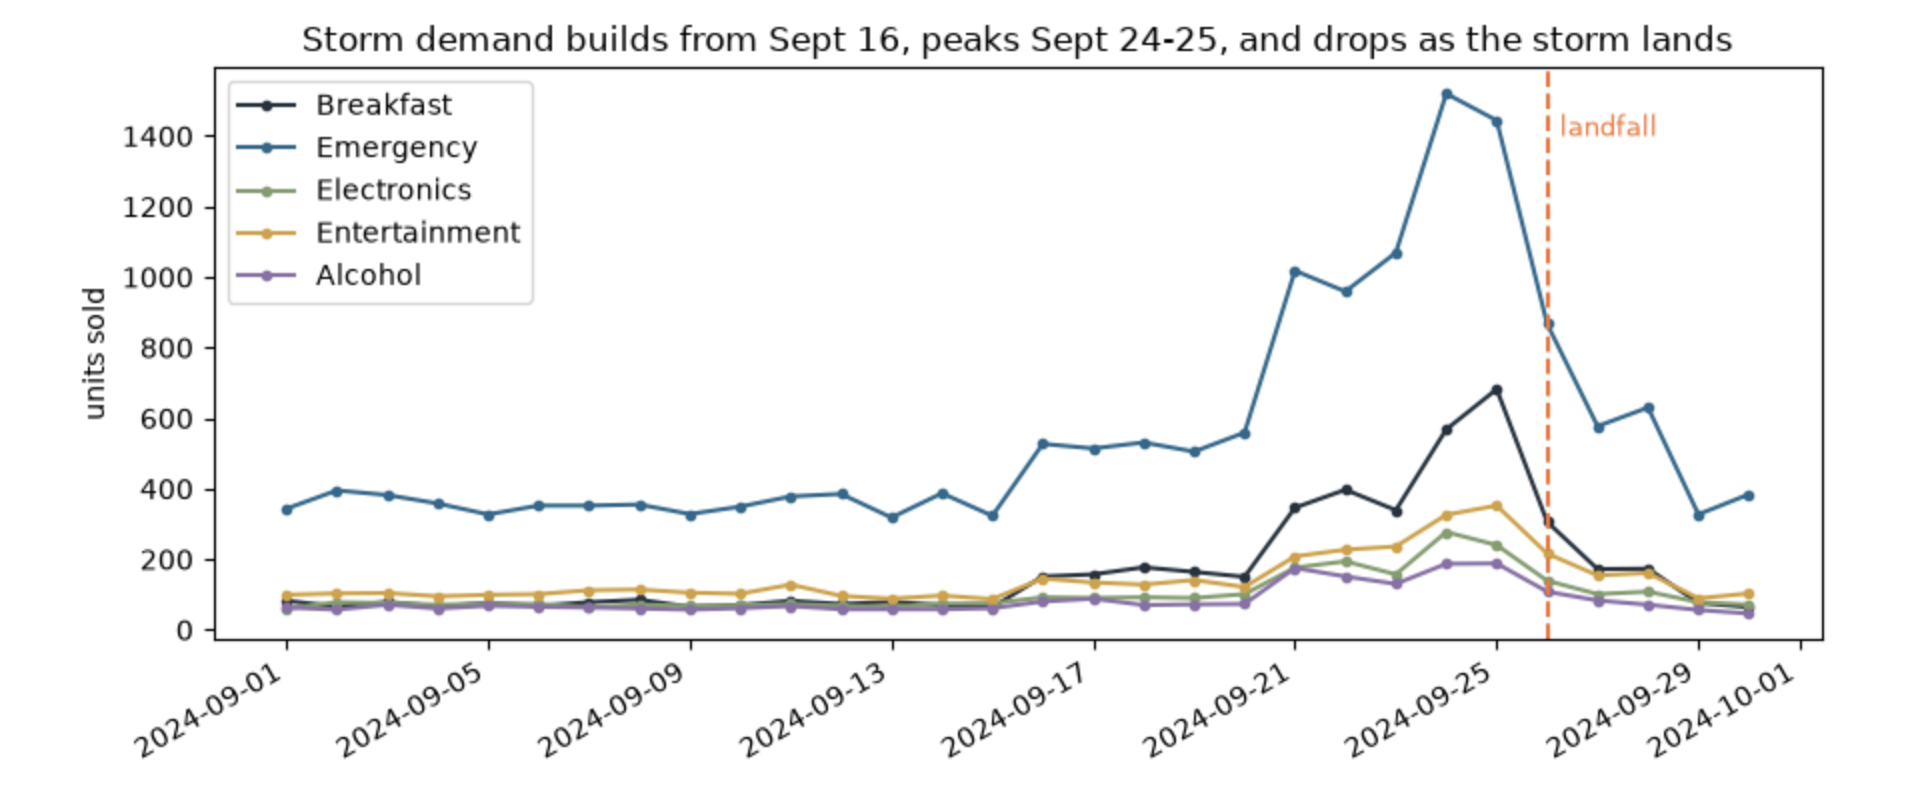

**Q1 answer:** Strawberry Pop-Tarts (the only Breakfast product) sold 5.1x more per day in the Sept 19 to 25 surge window than in the Sept 1 to 15 baseline, going from 73.5 to 378 units a day (+414%).

### Q2 — SKU consolidation

**TODO:** how many distinct SKUs you started with, how many canonical products you ended with, your largest consolidated family, and a before-and-after comparison showing what changes. Include the assertion proving consolidation did not change unit totals.

In [2]:
# Q2 numbers from team_notebook.ipynb
skus_before = 45
products_after = 20
largest_family = 'Strawberry Pop-Tarts (4 SKUs: PT-12, SKU#459812, POPTART-STRAW, PT_STRAWBERRY)'
largest_single_sku_units = 1385   # PT-12, the biggest of the four
consolidated_units = 5218

print(skus_before, 'SKUs ->', products_after, 'canonical products')
print('largest family:', largest_family)
print('before:', largest_single_sku_units, 'units for the biggest single SKU')
print('after: ', consolidated_units, 'units for the product')
print(f'the real number is {consolidated_units / largest_single_sku_units:.1f}x bigger than it looked')
print('transactions rows 25,532 -> 25,532 (the assertion is in step #9 of team_notebook.ipynb)')

45 SKUs -> 20 canonical products
largest family: Strawberry Pop-Tarts (4 SKUs: PT-12, SKU#459812, POPTART-STRAW, PT_STRAWBERRY)
before: 1385 units for the biggest single SKU
after:  5218 units for the product
the real number is 3.8x bigger than it looked
transactions rows 25,532 -> 25,532 (the assertion is in step #9 of team_notebook.ipynb)


**Q2 answer:** The 45 raw SKUs map to 20 canonical products, and the biggest family is Strawberry Pop-Tarts with 4 SKUs. The biggest single SKU showed 1385 units but the real total is 5218, 3.8x bigger. Row counts and unit totals did not change when I consolidated (25,532 rows before and after).

### Q3 — Weather correlation

**TODO:** the API call, the validated join, and the relationship you found. Include:

- the row count before and after the join, proving nothing was lost
- whether the data is live or fallback
- how many days the correlation is computed over

If your n is small, say so here rather than being asked about it on Monday.

In [3]:
# Q3 numbers from team_notebook.ipynb
source = 'live (Open-Meteo archive API, pulled with retries)'
rows_before_join = 30   # sales days
rows_after_join = 30
days_same_day = 30
days_at_best_lag = 28   # shifting the weather 2 days drops the last 2 days

print('data:', source)
print('join rows:', rows_before_join, '->', rows_after_join, '(preserved:', rows_before_join == rows_after_join, ')')
print('same-day correlation, wind r = 0.38 over', days_same_day, 'days')
print('best lag, wind 2 days later r = 0.83 over', days_at_best_lag, 'days')

data: live (Open-Meteo archive API, pulled with retries)
join rows: 30 -> 30 (preserved: True )
same-day correlation, wind r = 0.38 over 30 days
best lag, wind 2 days later r = 0.83 over 28 days


**Q3 answer:** Same-day weather barely tracks sales (wind r = 0.38), but sales line up best with the wind 2 days later (r = 0.83), so people pre-bought before the storm. However, this uses only 28 days (30 minus the 2 lost to the lag), one storm, and one weather location (Orlando).

### Q4 and Q5 — where they stand

**Q4 (stores and geography):** Q4 is done. Every store surged about 2.2 to 2.7x, and distance from landfall does not explain it (r = 0.23); Miami is the highest and Orlando the lowest.

**Q5 (signal or artifact):** Q5 is done. The board game surge is not an artifact, since the +250% only describes the two peak days and the signal holds across both files, products and stores.

### Self-check

In [4]:
progress = {
    'q1_multiple': 5.1,
    'q1_baseline_window': 'Sept 1 to 15, 2024',
    'q2_canonical_products': 20,
    'q3_join_rows_preserved': True,
    'q3_days_in_correlation': 28,
    'charts_with_message_titles': 4,  # Q1 x2, Q2, Q3 overlay (the Q3 wind scatter has a plain title)
    'notebook_runs_clean': True,   
    'repo_pushed': True,           
}

for label, value in progress.items():
    filled = not (value is None or value is False
                  or (isinstance(value, str) and value.startswith('TODO')))
    print('PASS' if filled else 'FAIL', '-', label, '=', value)
print()
print('ready for presentations:', all(
    not (v is None or v is False or (isinstance(v, str) and v.startswith('TODO')))
    for v in progress.values()))

PASS - q1_multiple = 5.1
PASS - q1_baseline_window = Sept 1 to 15, 2024
PASS - q2_canonical_products = 20
PASS - q3_join_rows_preserved = True
PASS - q3_days_in_correlation = 28
PASS - charts_with_message_titles = 4
PASS - notebook_runs_clean = True
PASS - repo_pushed = True

ready for presentations: True


### Write-up

**a)** One finding that surprised your team, and what you checked to make sure it was real rather than a bug.

**b)** One number you reported that you are least confident in, and why.

**a)** What surprised us most is that sales line up best with the wind 2 days later (r = 0.83), not the wind that day (r = 0.38). To check it was real and not a bug, I compared lags of 0 to 4 days (the correlation peaks at 2 and falls off on both sides), the same pattern shows up in every top category, and the join check confirmed all 30 sales days kept their weather.

**b)** The number I am least sure about is the 0.83 wind correlation. It uses only 28 days from one storm and one weather location (Orlando), so it is a strong pattern but not a proof. I also left out 884 of 25,532 transactions (3.5%) because they have no timestamp.